In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
# Load the dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Understanding Product Categories
#**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?
#1. **Frequency Tables**:
#    - Generate a frequency table for the product `category`.
#    - Which are the top 5 most listed product categories?

In [4]:
frequency_table = df['category'].value_counts()
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [5]:
top_5_categories = frequency_table.head(5)
top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

#2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. 
       *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

C:\Users\pccom\AppData\Local\Temp\ipykernel_13108\2447396351.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3");


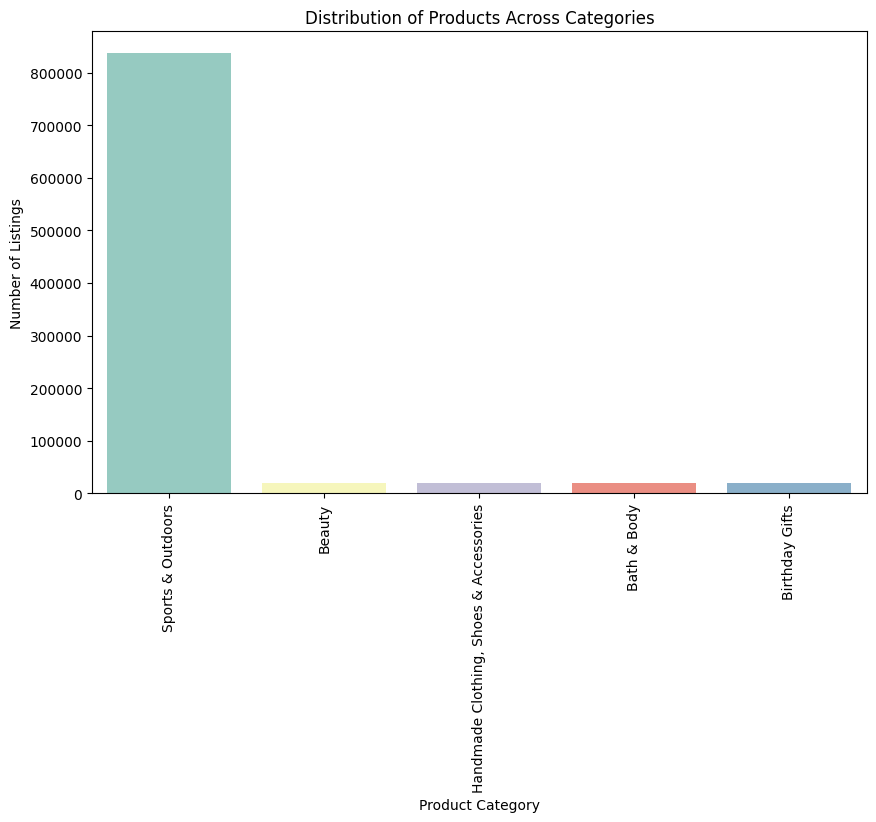

In [6]:
# Plotting a bar chart using the values from the top5 categories
plt.figure(figsize=(10,6))
sns.barplot(x=top_5_categories.index, y=top_5_categories.values, palette="Set3");
plt.xticks(rotation=90)
plt.title('Distribution of Products Across Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Listings')
plt.show()

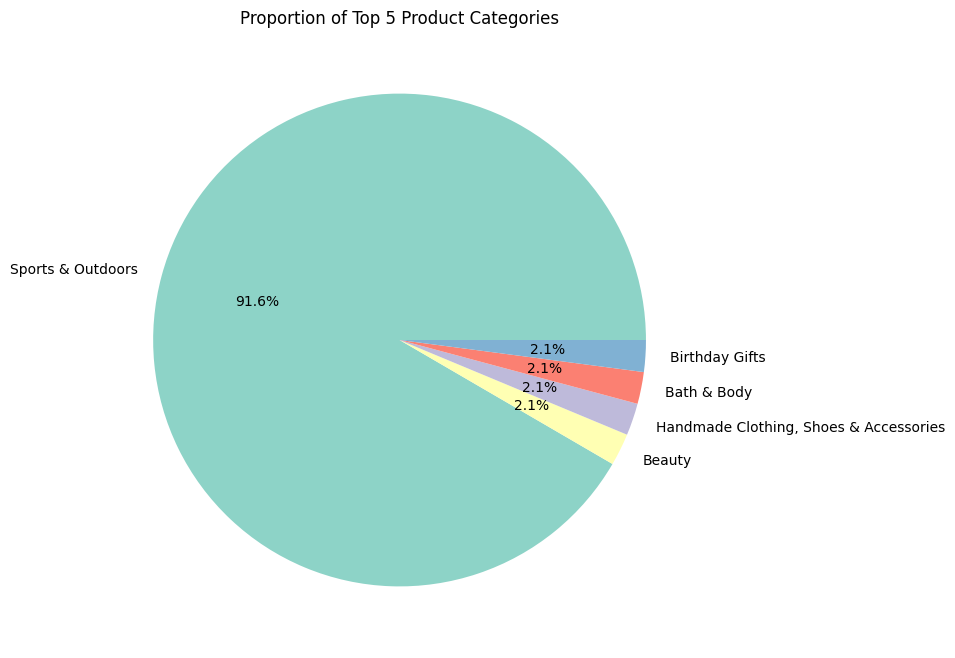

In [7]:
#pie chart for the top 5 categories
plt.figure(figsize=(8,8))
plt.pie(top_5_categories.values, labels=top_5_categories.index, autopct='%1.1f%%', colors=sns.color_palette("Set3"))
plt.title('Proportion of Top 5 Product Categories')
plt.show()

Sports & Outdoors appears to dominate the listings among the top 5 categories.

### Part 2: Delving into Product Pricing
**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?
#1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [8]:
df['price'].dtypes

dtype('float64')

In [9]:
df['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [ ]:
# Medidas de centralidad
print("La media es:", df['price'].mean())
print("La mediana es:", df['price'].median())
print("La moda es:", df['price'].mode())

La media es: 89.24380943923661
La mediana es: 19.09
La moda es: 0    9.99
Name: price, dtype: float64


La media es bastante alta, por lo que se ve es que hay productos muy caros que elevan el promedio. La diferencia entre la media (89.24) y la mediana (19.09) que representa el precio normal que paga un comprador, es muy grande, por lo que nos indica que la mayor parte de los productos tienen precios relativamente bajos. La moda (9.99) es el precio más común.

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

In [23]:
# Medidas de dispersión
print("La varianza es:", df['price'].var())
print("La desviación estandar es:", df['price'].std())
print("El rango es:", df['price'].max() - df['price'].min())
print("El rango intercuartilico (IQR) es:", df['price'].quantile(0.75) - df['price'].quantile(0.25))

La varianza es: 119445.48532254901
La desviación estandar es: 345.60886175349873
El rango es: 100000.0
El rango intercuartilico (IQR) es: 36.0


La varianza es muy alto por lo que indica que los precios se alejan mucho de la media. La desviación estandar es muy alta en comparación con la mediana y la moda, por lo que confirma que hay precios muy altos que aumenta mucho la dispersion de los datos. El rango nos indica que la diferencia entre el precio más caro y más barato es enorme. El resultado de IQR significa que la mayoria de productos tienen precios concentrados en valores bajos y medianos.

3# Visualizaciones

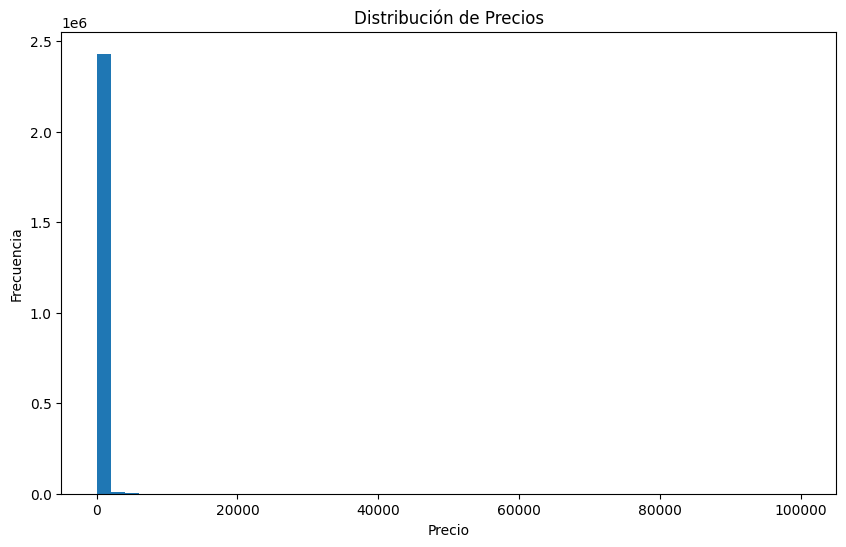

In [12]:
plt.figure(figsize=(10,6))
plt.hist(df['price'], bins=50)
plt.title("Distribución de Precios")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.show()


La mayoria de los productos estan concentrados en precios bajos.

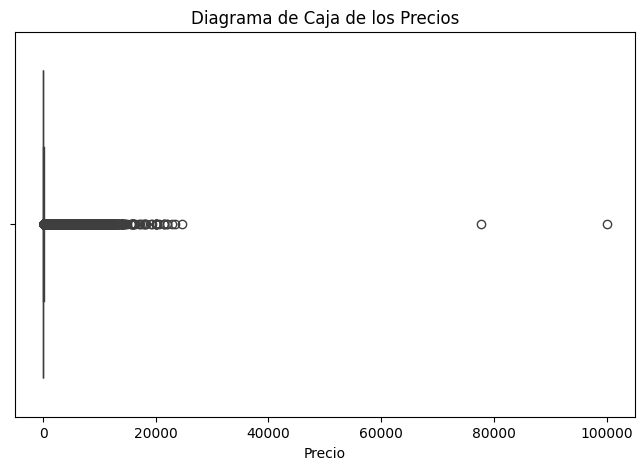

In [13]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['price'])
plt.title("Diagrama de Caja de los Precios")
plt.xlabel("Precio")
plt.show()


En comparación con el histograma se ve que hay productos extremadamente caros o de lujo que hace que estos valores afecten a la media pero no a la mediana.

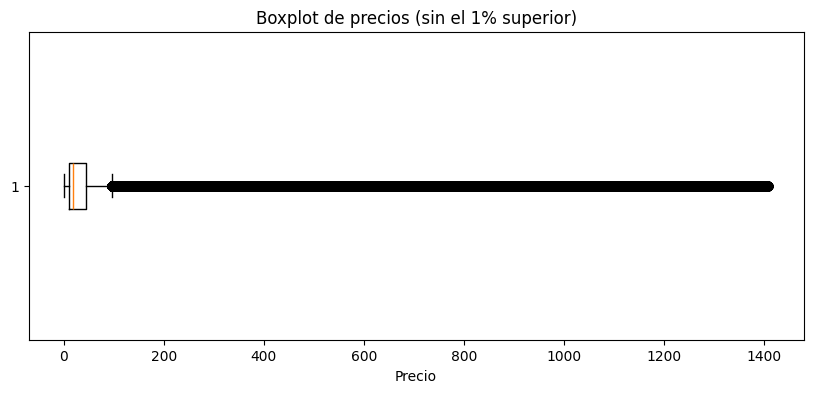

In [4]:
p99 = df["price"].quantile(0.99)
filtered = df[df["price"] <= p99]
plt.figure(figsize=(10,4))
plt.boxplot(filtered["price"], vert=False)
plt.title("Boxplot de precios (sin el 1% superior)")
plt.xlabel("Precio")
plt.show()

Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

In [14]:
df['stars'].dtypes

dtype('float64')

In [16]:
df['stars'].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [ ]:
# Check de valores de stars
df['stars'].value_counts()

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

In [17]:
# Medidas de centralidad
print("La media es:", df['stars'].mean())
print("La mediana es:", df['stars'].median())
print("La moda es:", df['stars'].mode())

La media es: 2.152836472966066
La mediana es: 0.0
La moda es: 0    0.0
Name: stars, dtype: float64


La media (2.15) indica que aunque existes calificaciones altas, la mayoría de productos reciben calificaciones bajas. La mediana siendo (0) significa que mas de la mitad de los productos no tienen calificaciones positivas. La moda (0) confirma que la calificacion más común entre los productos es 0.

Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

In [25]:
# Medidas de dispersión
print("La varianza es:", df['stars'].var())
print("La desviación estandar es:", df['stars'].std())
print("El rango es:", df['stars'].max() - df['stars'].min())
print("El rango intercuartilico (IQR) es:", df['stars'].quantile(0.75) - df['stars'].quantile(0.25))

La varianza es: 4.817434029796864
La desviación estandar es: 2.194865378513421
El rango es: 5.0
El rango intercuartilico (IQR) es: 4.4


La varianza y la desviación estandar, tiene valores moderados-altos que indican que hay variación significativa en las calificaciones, aunque muchos productos tiene stars = 0, unos pocos tienes valores altos hasta (5), lo que aumenta la dispersión. El rango nos indica que las calificaciones van de 0 a 5. El IQR el valor que nos da, nos indica que el 50% de los productos reciben calificaciones entre 0 y 4.4, esto muestra que, aunque la mayoría tiene calificaciones bajas, hay productos con calificaciones muy altas.

Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?


In [26]:
from scipy.stats import skew, kurtosis

# Asimetría y curtosis
skewness = skew(df['stars'])
kurt = kurtosis(df['stars'])

print("Asimetría (skewness):", skewness)
print("Curtosis (kurtosis):", kurt)


Asimetría (skewness): 0.08120730776283251
Curtosis (kurtosis): -1.9260046425498398


Asimetria = 0.08 la distribucion es casi simetrica, no hay sesgo fuerte hacia calificaciones bajas o altas, aunque la mayoría de los valores son 0, la distribucion se mantiene equilibrada.
Curtosis = -1.92 valor negativo significa que tiene menos pico y colas mas anchas, los valores extremos (0 y 5) están más dispersos que en una normal.

Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

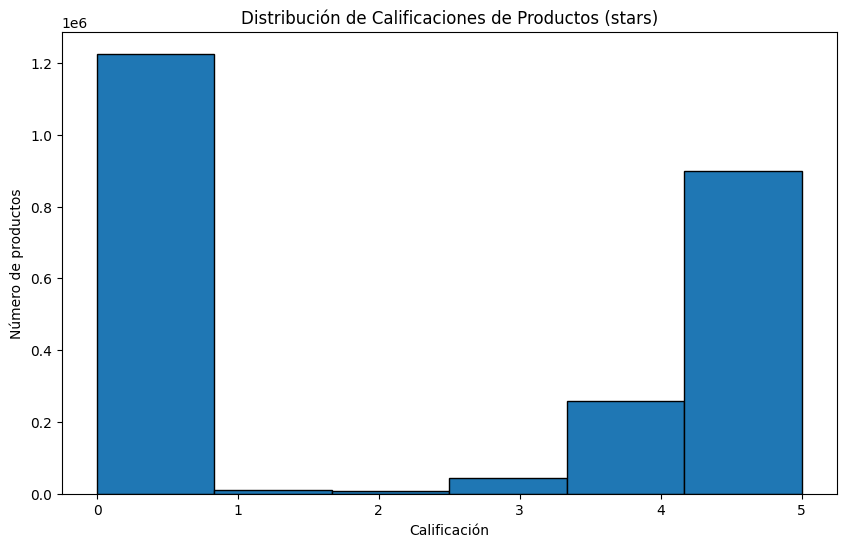

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.hist(df['stars'], bins=6, edgecolor='black')  # bins=6 para calificaciones 0,1,2,3,4,5
plt.title("Distribución de Calificaciones de Productos (stars)")
plt.xlabel("Calificación")
plt.ylabel("Número de productos")
plt.xticks(range(0,6))  # Etiquetas para 0,1,2,3,4,5
plt.show()


La calificación más común es 0, mas del 50% del dataset tiene 0 estrellas, las estrellas 1, 2 y 3 indica que menos productos tienen esas calificaciones y luego hay productos bien valorados, pero son muchos menos que los que tienen 0 estrellas